# Split Sentinel: implementation and real-data analysis

This notebook contains the working audit algorithm, not a wrapper around a hidden implementation. It prepares the official UCI Adult split, runs the checks, verifies agreement with the installed package, and examines what the findings mean. The scanner is deterministic; it does not train a classifier. A count of matching rows is not a model score or proof of harmful leakage.

Install `python -m pip install -e ".[dev]"` and `jupyterlab matplotlib numpy`. Data stay in ignored `data/`. Executed outputs below contain only aggregates. Source: Becker & Kohavi, UCI Adult, CC BY 4.0, DOI 10.24432/C5XW20.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, io, contextlib
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/leakage_audit/audit.py').exists()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
RUN = ROOT / 'data/interim' / ('analysis-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
RUN.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Fresh analysis directory:', RUN.relative_to(ROOT))

Fresh analysis directory: data\interim\analysis-20261016T075426839713Z


## Configuration and parsing
The public configuration makes label inspection and approximate matching explicit. Numeric normalization is opt-in because identifiers and large integers should not silently become floats.

In [2]:
from collections import Counter

In [3]:
from collections.abc import Mapping

In [4]:
from dataclasses import dataclass

In [5]:
from datetime import datetime, timezone, timedelta

In [6]:
import csv

In [7]:
import math

In [8]:
from decimal import Decimal, InvalidOperation

In [9]:
from pathlib import Path

In [10]:
MISSING = {"", "na", "nan", "null", "none"}

### Configuration validation

In [11]:
@dataclass(frozen=True)
class AuditConfig:
    target: str
    entity: str | None = None
    time: str | None = None
    embargo_seconds: float = 0
    proxy_threshold: float = .98
    shift_threshold: float = .3
    numeric_duplicate_columns: tuple[str, ...] = ()
    check_target_quality: bool = False
    check_near_duplicates: bool = False

    def __post_init__(self):
        names=[name for name in (self.target,self.entity,self.time) if name is not None]
        if any(not isinstance(name,str) or not name.strip() for name in names):
            raise ValueError("Configured column names must be nonempty strings")
        if len(names)!=len(set(names)):
            raise ValueError("Target, entity and time columns must be distinct")
        if not isinstance(self.numeric_duplicate_columns, tuple) or any(not isinstance(c, str) or not c.strip() for c in self.numeric_duplicate_columns) or len(set(self.numeric_duplicate_columns)) != len(self.numeric_duplicate_columns):
            raise ValueError("Numeric duplicate columns must be a tuple of distinct nonempty names")
        if not isinstance(self.check_target_quality, bool):
            raise ValueError("check_target_quality must be boolean")
        if not isinstance(self.check_near_duplicates, bool):
            raise ValueError("check_near_duplicates must be boolean")
        values=(self.embargo_seconds,self.proxy_threshold,self.shift_threshold)
        if any(not isinstance(v,(int,float)) for v in values):
            raise ValueError("Embargo and thresholds must be numeric")
        try:
            finite=all(math.isfinite(v) for v in values)
        except OverflowError:
            finite=False
        if not finite:
            raise ValueError("Embargo and thresholds must be finite")
        if self.embargo_seconds < 0:
            raise ValueError("embargo_seconds must be finite and nonnegative")
        if not 0 < self.proxy_threshold <= 1 or not 0 < self.shift_threshold <= 1:
            raise ValueError("thresholds must be in (0, 1]")

In [12]:
def missing(value):
    return value is None or str(value).strip().lower() in MISSING

### CSV schema checks

In [13]:
def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f,strict=True)
        if not reader.fieldnames or any(not name.strip() for name in reader.fieldnames) or len(set(reader.fieldnames)) != len(reader.fieldnames):
            raise ValueError("CSV requires nonempty, unique column names")
        try:
            rows = list(reader)
        except csv.Error as error:
            raise ValueError(f"Malformed CSV: {error}") from error
        if any(None in r or any(v is None for v in r.values()) for r in rows):
            raise ValueError("CSV row width differs from header")
        return rows

In [14]:
def number(value):
    try:
        result = float(value)
        return result if math.isfinite(result) else None
    except (ValueError, TypeError, OverflowError):
        return None

In [15]:
def nonfinite(value):
    """Recognized missing markers stay missing; other nonfinite numbers are invalid."""
    if missing(value): return False
    try:
        return not math.isfinite(float(value))
    except (ValueError, TypeError):
        return False
    except OverflowError:
        return True

In [16]:
def usable(value):
    return not missing(value) and not nonfinite(value)

### Training-only numeric association

In [17]:
def correlation(x, y):
    # Scale finite values first to avoid overflow in means, squares and products.
    sx,sy=max(abs(v) for v in x),max(abs(v) for v in y)
    if not sx or not sy: return 0.
    x,y=[v/sx for v in x],[v/sy for v in y]
    mx,my=math.fsum(x)/len(x),math.fsum(y)/len(y)
    vx,vy=math.fsum((v-mx)**2 for v in x),math.fsum((v-my)**2 for v in y)
    denominator=math.sqrt(vx)*math.sqrt(vy)
    result=math.fsum((a-mx)*(b-my) for a,b in zip(x,y))/denominator if denominator else 0.
    return max(-1.,min(1.,result))

### Empirical distribution distance

In [18]:
def ks_distance(x, y):
    """Exact empirical CDF distance (effect size, not a p-value)."""
    a, b = Counter(x), Counter(y)
    ca = cb = 0
    distance = 0.
    for value in sorted(a.keys() | b.keys()):
        ca += a[value]
        cb += b[value]
        distance = max(distance, abs(ca/len(x)-cb/len(y)))
    return distance

In [19]:
def at_least(value, threshold):
    """Inclusive thresholds with a tiny tolerance for empirical-fraction rounding."""
    return value >= threshold or math.isclose(value,threshold,rel_tol=0,abs_tol=1e-12)

### Timestamp normalization

In [20]:
def parse_time(value):
    parsed = datetime.fromisoformat(str(value).replace("Z", "+00:00"))
    # Naive input is explicitly interpreted as UTC.
    return parsed.replace(tzinfo=timezone.utc) if parsed.tzinfo is None else parsed.astimezone(timezone.utc)

### Full audit: exact matches, near matches, label quality, entity/time overlap, proxies and shift

In [21]:
def audit(train, test, config):
    try:
        train,test=list(train),list(test)
    except TypeError as error:
        raise ValueError("Splits must be iterables of row mappings") from error
    if not train or not test:
        raise ValueError("Both splits must contain rows")
    if any(not isinstance(row,Mapping) for row in train+test):
        raise ValueError("Every row must be a mapping of column names to scalar values")
    columns = set(train[0])
    if any(not isinstance(c,str) or not c.strip() for c in columns):
        raise ValueError("Column names must be nonempty strings")
    if any(set(r) != columns for r in train + test):
        raise ValueError("Splits must have identical schemas")
    if any(not isinstance(v,(str,int,float,bool,type(None))) for row in train+test for v in row.values()):
        raise ValueError("Tabular values must be scalar strings, numbers, booleans or None")
    required = {config.target} | {c for c in (config.entity, config.time) if c}
    if not required <= columns:
        raise ValueError(f"Missing configured columns: {sorted(required-columns)}")
    findings = []
    def add(kind, severity, **evidence):
        findings.append(dict(kind=kind, severity=severity, evidence=evidence))
    features = sorted(columns - required)
    if not features:
        raise ValueError("At least one non-metadata feature is required")
    if not set(config.numeric_duplicate_columns) <= set(features):
        raise ValueError("Numeric duplicate columns must be non-metadata feature columns")
    if config.check_near_duplicates and not 2 <= len(features) <= 64:
        raise ValueError("Near-duplicate audit requires between 2 and 64 features")
    def signature(row):
        values = []
        for col in features:
            value = row[col]
            if col in config.numeric_duplicate_columns:
                if missing(value):
                    value = ('missing',)
                else:
                    try:
                        normalized = Decimal(str(value).strip())
                    except InvalidOperation as error:
                        raise ValueError(f"Configured numeric duplicate column contains nonnumeric data: {col}") from error
                    if not normalized.is_finite():
                        raise ValueError(f"Configured numeric duplicate column contains nonfinite data: {col}")
                    value = ('numeric', normalized)
            values.append(value)
        return tuple(values)
    # Validate explicitly numeric columns even on otherwise unusable rows.
    if config.numeric_duplicate_columns:
        for row in train + test:
            signature(row)
    signatures = {signature(r) for r in train if any(usable(r[c]) for c in features)}
    duplicates = sum(any(usable(r[c]) for c in features) and signature(r) in signatures for r in test)
    if duplicates:
        add("cross_split_duplicates", "high", test_rows=duplicates, test_fraction=duplicates/len(test), columns=features,
            numeric_normalization_columns=list(config.numeric_duplicate_columns))
    if config.check_near_duplicates:
        # Process one projection at a time to bound memory. Keep at most two
        # distinct omitted values: sufficient to establish an unequal witness.
        eligible_test = [(index, signature(row)) for index, row in enumerate(test)
                         if any(usable(row[c]) for c in features)]
        matched_rows, by_column = set(), {}
        for position, column in enumerate(features):
            projections = {}
            for values in signatures:
                key = values[:position] + values[position+1:]
                bucket = projections.setdefault(key, set())
                if len(bucket) < 2:
                    bucket.add(values[position])
            count = 0
            for index, values in eligible_test:
                if values in signatures:
                    continue
                key = values[:position] + values[position+1:]
                witnesses = projections.get(key, ())
                if any(value != values[position] for value in witnesses):
                    matched_rows.add(index)
                    count += 1
            if count:
                by_column[column] = count
        if matched_rows:
            add('cross_split_near_duplicates', 'review', test_rows=len(matched_rows),
                test_fraction=len(matched_rows)/len(test), differing_column_counts=by_column,
                excluded_exact_matches=True,
                interpretation='Exactly one feature differs; chance matches and legitimate repeated measurements are possible.')
    if config.check_target_quality:
        target_quality = {}
        for name, rows in [('train', train), ('test', test)]:
            absent = sum(missing(r[config.target]) for r in rows)
            invalid = sum(nonfinite(r[config.target]) for r in rows)
            if absent or invalid:
                target_quality[name] = {'missing': absent, 'nonfinite': invalid, 'rows': len(rows)}
        if target_quality:
            add('target_quality', 'review', splits=target_quality)
        # Explicit opt-in: consults heldout labels for quality, never fits proxy scores.
        labels_by_signature = {}
        for row in train:
            if usable(row[config.target]) and any(usable(row[c]) for c in features):
                labels_by_signature.setdefault(signature(row), set()).add(row[config.target])
        conflicts = sum(len(labels) > 1 for labels in labels_by_signature.values())
        if conflicts:
            add('within_train_label_conflicts', 'review', feature_groups=conflicts)
        cross_conflicts = sum(usable(r[config.target]) and any(usable(r[c]) for c in features)
                              and signature(r) in labels_by_signature
                              and any(label != r[config.target] for label in labels_by_signature[signature(r)]) for r in test)
        if cross_conflicts:
            add('cross_split_label_conflicts', 'review', test_rows=cross_conflicts,
                interpretation='Matching feature vectors have contradictory labels; legitimate stochastic outcomes are possible.')
    if config.entity:
        entities = {r[config.entity] for r in train if not missing(r[config.entity])}
        overlap = sum(not missing(r[config.entity]) and r[config.entity] in entities for r in test)
        if overlap:
            add("entity_overlap", "review", test_rows=overlap, test_fraction=overlap/len(test))
    if config.time:
        try:
            train_times = [parse_time(r[config.time]) for r in train]
            test_times = [parse_time(r[config.time]) for r in test]
        except (ValueError, TypeError, OverflowError) as e:
            raise ValueError("Every configured timestamp must be a valid ISO-8601 datetime") from e
        try:
            cutoff = max(train_times) + timedelta(seconds=config.embargo_seconds)
        except (OverflowError,ValueError) as error:
            raise ValueError("Temporal cutoff exceeds the supported datetime range") from error
        overlap = sum(t <= cutoff for t in test_times)
        if overlap:
            add("temporal_overlap", "high", test_rows=overlap, cutoff=cutoff.isoformat(), embargo_seconds=config.embargo_seconds)
    # Train-only associations avoid selecting features using test labels.
    for col in features:
        invalid_train=sum(nonfinite(r[col]) for r in train)
        invalid_test=sum(nonfinite(r[col]) for r in test)
        if invalid_train or invalid_test:
            add("nonfinite_values", "review", column=col, train_rows=invalid_train, test_rows=invalid_test)
        pairs = [(r[col], r[config.target]) for r in train if usable(r[col]) and usable(r[config.target])]
        if len(pairs) >= 20:
            x, y = zip(*pairs)
            nx, ny = [number(v) for v in x], [number(v) for v in y]
            if all(v is not None for v in nx + ny):
                corr = abs(correlation(nx, ny))
                if at_least(corr,config.proxy_threshold):
                    add("target_proxy", "review", column=col, method="absolute_pearson", score=corr, rows=len(pairs))
            # Restrict mapping checks to repeated, low-cardinality categories.
            counts = Counter(x)
            mapping = {}
            for a,b in pairs:
                mapping.setdefault(a, set()).add(b)
            if 1 < len(counts) <= min(20, len(pairs)//5) and min(counts.values()) >= 5 and len(set(y)) > 1 and all(len(v)==1 for v in mapping.values()):
                add("target_proxy", "review", column=col, method="deterministic_category_mapping", score=1., rows=len(pairs))
        a = [r[col] for r in train if usable(r[col])]
        b = [r[col] for r in test if usable(r[col])]
        ma=sum(missing(r[col]) for r in train)/len(train)
        mb=sum(missing(r[col]) for r in test)/len(test)
        if at_least(abs(ma-mb),config.shift_threshold):
            add("missingness_shift", "review", column=col, train_fraction=ma, test_fraction=mb)
        if not a or not b:
            continue
        na, nb = [number(v) for v in a], [number(v) for v in b]
        if all(v is not None for v in na + nb):
            distance, method = ks_distance(na, nb), "empirical_ks"
        else:
            ca, cb = Counter(a), Counter(b)
            keys=sorted(ca.keys() | cb.keys(),key=lambda value:(type(value).__name__,repr(value)))
            distance = min(1.,.5*math.fsum(abs(ca[k]/len(a)-cb[k]/len(b)) for k in keys))
            method = "total_variation"
        if at_least(distance,config.shift_threshold):
            add("distribution_shift", "review", column=col, method=method, score=distance, train_nonmissing=len(a), test_nonmissing=len(b))
    return {"schema_version": 1, "rows": {"train": len(train), "test": len(test)}, "findings": findings,
            "configuration": {'numeric_duplicate_columns': list(config.numeric_duplicate_columns),
                              'check_target_quality': config.check_target_quality,
                              'check_near_duplicates': config.check_near_duplicates},
            "limitations": ["Signals require domain review; distribution shift is not proof of leakage.", "Cannot detect preprocessing fit on test data, label availability or semantic duplicates.", "Exact feature-row comparisons exclude configured target/entity/time; missing tokens are documented.", "Numeric proxy detection uses train-only linear association; nonlinear proxies may be missed."]}

## Official source preparation
The following code is the production Adult parser and checksum-verified preparation routine. It keeps the published train/test split and writes the new report into this run directory.

In [22]:
from collections import Counter

In [23]:
import csv

In [24]:
import hashlib

In [25]:
import io

In [26]:
import json

In [27]:
from pathlib import Path

In [28]:
from urllib.request import urlopen

In [29]:
import zipfile

In [30]:
URL = 'https://archive.ics.uci.edu/static/public/2/adult.zip'

In [31]:
ARCHIVE_SHA256 = '7537312dd56c2b98035880805ce99e68183a30ee468aa5329d6df0fbb3cc21bb'

In [32]:
SOURCE_HASHES = {'adult.data': '5b00264637dbfec36bdeaab5676b0b309ff9eb788d63554ca0a249491c86603d',
                 'adult.test': 'a2a9044bc167a35b2361efbabec64e89d69ce82d9790d2980119aac5fd7e9c05'}

In [33]:
COLUMNS = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status',
           'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss',
           'hours_per_week', 'native_country', 'target']

In [34]:
def parse(content):
    rows = []
    for row in csv.reader(io.StringIO(content.decode('ascii')), skipinitialspace=True):
        if not row or row[0].startswith('|'):
            continue
        if len(row) != len(COLUMNS):
            raise ValueError('Unexpected Adult source row width')
        values = [value.strip() for value in row]
        values[-1] = values[-1].removesuffix('.')
        if values[-1] not in {'<=50K', '>50K'}:
            raise ValueError('Unexpected Adult income label')
        rows.append(dict(zip(COLUMNS, [None if v == '?' else v for v in values])))
    return rows

In [35]:
def prepare_official_adult(directory='data/external/adult', report='docs/adult-validation-results.json', processed='data/processed/adult'):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory/'adult.zip'
    if not path.exists():
        with urlopen(URL, timeout=60) as response:
            path.write_bytes(response.read())
    content = path.read_bytes()
    if hashlib.sha256(content).hexdigest() != ARCHIVE_SHA256:
        raise ValueError('UCI Adult archive checksum changed')
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        sources = {name: archive.read(name) for name in SOURCE_HASHES}
        for name, data in sources.items():
            if hashlib.sha256(data).hexdigest() != SOURCE_HASHES[name]:
                raise ValueError('UCI Adult source checksum mismatch')
        (directory/'adult.names').write_bytes(archive.read('adult.names'))
    train, test = parse(sources['adult.data']), parse(sources['adult.test'])
    if (len(train), len(test)) != (32561, 16281):
        raise ValueError('Official Adult split size changed')
    processed = Path(processed)
    processed.mkdir(parents=True, exist_ok=True)
    for name, rows in [('train', train), ('test', test)]:
        with (processed/(name+'.csv')).open('w', encoding='utf-8', newline='') as handle:
            writer = csv.DictWriter(handle, fieldnames=COLUMNS)
            writer.writeheader()
            writer.writerows(rows)
    result = audit(train, test, AuditConfig('target', check_target_quality=True))
    # Independent exact-vector reference counts; no injected or resplit observations.
    signature = lambda row: tuple(row[c] for c in COLUMNS[:-1])
    training = Counter(signature(r) for r in train)
    heldout = Counter(signature(r) for r in test)
    overlap = sum(count for key, count in heldout.items() if key in training)
    detected = next((f['evidence']['test_rows'] for f in result['findings'] if f['kind'] == 'cross_split_duplicates'), 0)
    if detected != overlap:
        raise AssertionError('Audit differs from independent exact-vector overlap count')
    report_data = {'provenance': {'source': URL, 'source_page': 'https://archive.ics.uci.edu/dataset/2/adult',
                                 'attribution': 'Becker, B. & Kohavi, R. (1996). Adult. UCI Machine Learning Repository.',
                                 'doi': 'https://doi.org/10.24432/C5XW20', 'license': 'CC BY 4.0',
                                 'archive_sha256': ARCHIVE_SHA256, 'source_sha256': SOURCE_HASHES},
                   'preprocessing': 'Strip field whitespace, remove documented test-label terminal period, map ? to None; no row removal or resplitting.',
                   'audit': result, 'independent_reference': {'cross_split_matching_test_rows': overlap,
                         'cross_split_matching_feature_groups': len(set(training) & set(heldout)),
                         'repeated_training_feature_groups': sum(count > 1 for count in training.values()),
                         'extra_training_copies': sum(count - 1 for count in training.values() if count > 1)},
                   'interpretation': 'Unmodified official records contain repeated feature vectors. This is an observed integrity signal, not proof the same individual crossed splits; no person IDs are available.',
                   'limitations': ['No expert natural-leakage labels, so sensitivity/false-positive rate cannot be estimated.',
                                   'Demographic features are used only for split diagnostics; no income model or fairness claim is made.',
                                   'Target-quality option consults heldout labels for diagnostics, never for model fitting.']}
    destination = Path(report)
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(report_data, indent=2, allow_nan=False)+'\n', encoding='utf-8', newline='\n')
    print(json.dumps({'rows': result['rows'], 'reference': report_data['independent_reference'], 'finding_kinds': [f['kind'] for f in result['findings']]}, indent=2))
    return report_data

In [36]:
with contextlib.redirect_stdout(io.StringIO()):
    prepared = prepare_official_adult(report=RUN / 'source-audit.json')
train = read_csv('data/processed/adult/train.csv')
test = read_csv('data/processed/adult/test.csv')
print({'training_rows': len(train), 'heldout_rows': len(test), 'features': len(train[0])-1})
print('Archive SHA256:', ARCHIVE_SHA256)

{'training_rows': 32561, 'heldout_rows': 16281, 'features': 14}
Archive SHA256: 7537312dd56c2b98035880805ce99e68183a30ee468aa5329d6df0fbb3cc21bb


## Run the inline implementation and compare it with the package
This checks that the readable code above and the shipped library produce exactly the same findings on real records. No labels are injected and no source rows are removed.

In [37]:
result = audit(train, test, AuditConfig('target', check_near_duplicates=True))
from leakage_audit.audit import audit as package_audit, AuditConfig as PackageConfig
reference = package_audit(train, test, PackageConfig('target', check_near_duplicates=True))
assert result == reference
(RUN / 'inline-audit.json').write_text(json.dumps(result, indent=2))
print('Inline/package agreement:', result == reference)
for finding in result['findings']:
    print(finding['kind'], finding['severity'])

Inline/package agreement: True
cross_split_duplicates high
cross_split_near_duplicates review


## How common are the matching feature vectors?
Exact and one-feature matches use different definitions and should not be added together. Near matching excludes exact matches. Neither definition establishes that two records describe the same person.

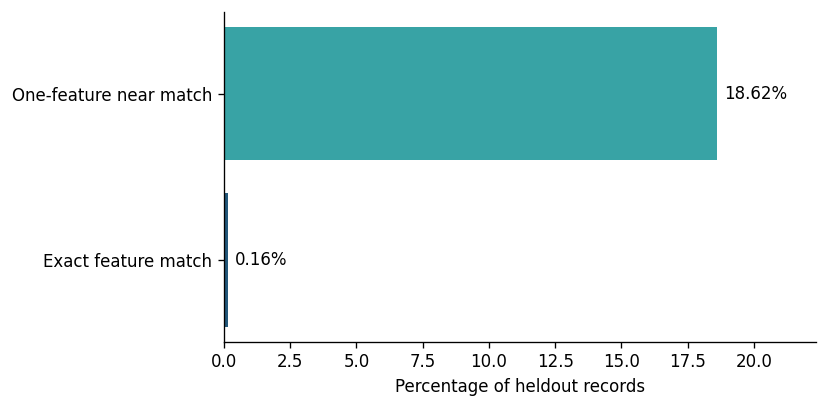

In [38]:
exact = next(f['evidence']['test_rows'] for f in result['findings'] if f['kind']=='cross_split_duplicates')
near = next(f['evidence'] for f in result['findings'] if f['kind']=='cross_split_near_duplicates')
fig, ax = plt.subplots(figsize=(7, 3.5))
labels = ['Exact feature match', 'One-feature near match']
values = [exact / len(test) * 100, near['test_rows'] / len(test) * 100]
bars = ax.barh(labels, values, color=['#22577a', '#38a3a5'])
ax.bar_label(bars, labels=[f'{v:.2f}%' for v in values], padding=4)
ax.set(xlabel='Percentage of heldout records', xlim=(0, max(values)*1.2))
fig.tight_layout(); fig.savefig(RUN / 'match-rates.png'); plt.show()

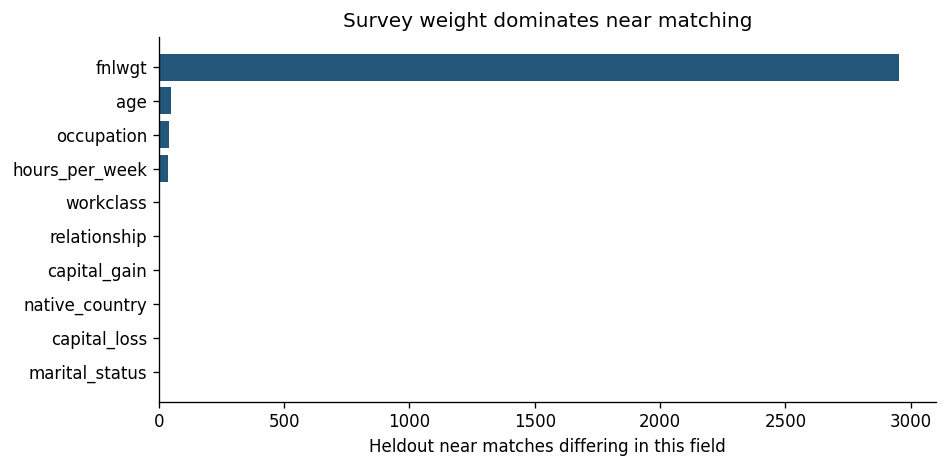

Survey-weight-only matches: 2953


In [39]:
counts = near['differing_column_counts']
ordered = sorted(counts, key=counts.get)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ordered, [counts[c] for c in ordered], color='#22577a')
ax.set(xlabel='Heldout near matches differing in this field', title='Survey weight dominates near matching')
fig.tight_layout(); fig.savefig(RUN / 'near-match-fields.png'); plt.show()
print('Survey-weight-only matches:', counts.get('fnlwgt', 0))

## Interpretation
The official split has 26 exact feature matches and 3,032 one-feature near matches; 2,953 near matches differ in survey weight. That concentration is a reason to inspect the dataset construction, not a reason to claim 18.6% harmful leakage. Adult has no person identifiers or expert leakage labels, so detection precision and recall are unknown. The supporting notebooks examine source distributions and independent verification.